In [118]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.special as sp
import IPython
import time

In [119]:
f = lambda x: 100 * (np.sin(2 * np.pi * x) * (1/((x-3)**2 + 0.1)))

n, N = 5, 500
max_n = 15
X = np.linspace(-1, 1, N)

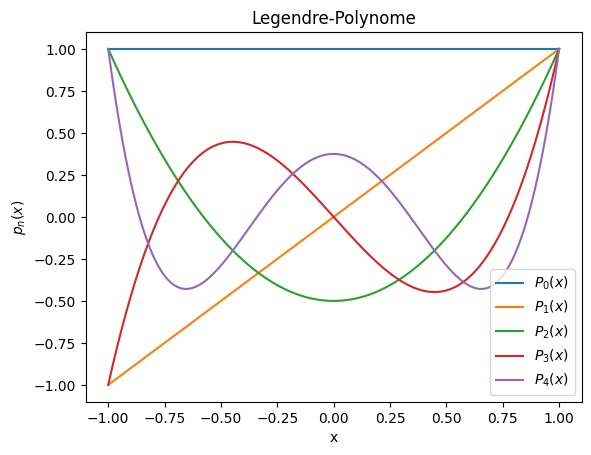

In [120]:
for i in range(n):
    y = sp.eval_legendre(i, X)
    plt.plot(X, y, label=r'$P_{}(x)$'.format(i))

plt.title("Legendre-Polynome")
plt.xlabel("x")
plt.ylabel(r'$p_n(x)$')
plt.legend()

Die folgende Zelle illustriert die Legendre-Nullstellen und -Gewichte für verschiedene $n$:

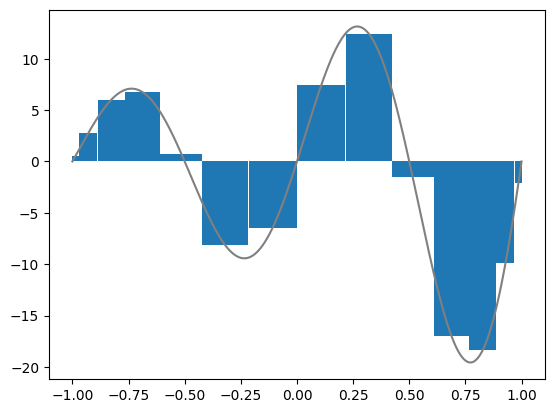

In [121]:
approx = []

k = np.arange(1, max_n, 1)
for i in k:
    x, w = sp.roots_legendre(i)

    approx.append(np.sum(f(x)*w))

    plt.plot(X, f(X), color="gray")
    plt.bar(x, f(x), width=w)

    # time.sleep(0.3)
    IPython.display.clear_output(True)
    plt.show()


Scipy Quad:	-2.7763412857573977

n	approx	rel_error
1:	 0.000	 1.00e+00
2:	-4.203	 5.14e-01
3:	-7.039	 1.54e+00
4:	-1.143	 5.88e-01
5:	-3.032	 9.21e-02
6:	-2.754	 8.10e-03
7:	-2.778	 4.63e-04
8:	-2.776	 1.88e-05
9:	-2.776	 5.74e-07
10:	-2.776	 1.38e-08
11:	-2.776	 2.68e-10
12:	-2.776	 4.32e-12
13:	-2.776	 5.84e-14
14:	-2.776	 1.60e-15


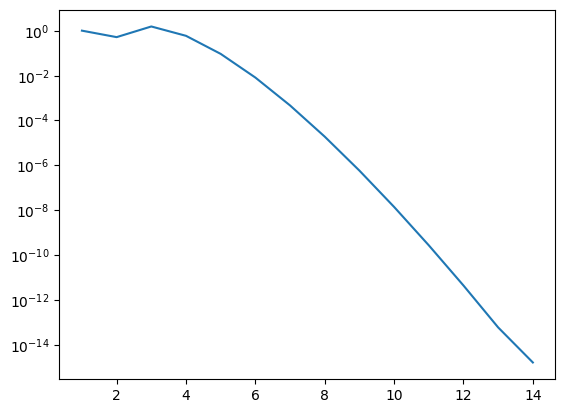

In [122]:
q = scipy.integrate.quad(f, -1, 1)[0]

errors = np.abs((np.array(approx) - q) / q)
plt.semilogy(k, errors)

print(f"Scipy Quad:\t{q}")
print(f"\nn\tapprox\trel_error")
for i, a, e in zip(k, approx, errors):
    print(f"{i}:\t{a:>6.3f}\t{e:>9.2e}")